In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import data

In [2]:
dataset = "UK"

In [3]:
path = {"UK": "", "HKJC": "hkjc-"}[dataset]

events = pd.read_parquet(f"data/{path}events.parquet")
races = pd.read_parquet(f"data/{path}races.parquet")
runners = pd.read_parquet(f"data/{path}runners.parquet")

In [4]:
events

,location,event_date
event_id,,
1824,Bev,2019-09-24
3516,ChelmC,2019-09-24
11890,Ling,2019-09-24
21095,Warw,2019-09-24
14768,Newcastle,2026-01-10
...,...,...
13190,Muss,2017-05-04
896,Ayr,2021-08-09
17352,Ripon,2021-08-09


In [5]:
races

,race_type,race_time,distance_f,event_id,race_no
race_id,,,,,
162764294,Hcap,2019-09-24 15:05:00,7,1824,3
162764320,Hcap,2019-09-24 17:45:00,10,1824,8
162764284,Nov Stks,2019-09-24 14:00:00,5,1824,1
162764331,Nov Stks,2019-09-24 17:25:00,7,3516,2
162764361,Hcap,2019-09-24 20:30:00,14,3516,8
...,...,...,...,...,...
186160695,Nov Stks,2021-08-09 15:35:00,7,896,4
186161070,Hcap,2021-08-09 19:55:00,5,17352,5
186161164,App Hcap,2021-08-09 17:35:00,6,22091,2


In [6]:
runners

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol
selection_id,,,,,,,,,,,,,,
8709395,162764294,Zylan,False,23.000000,0.043478,18.397112,10.189857,22.00,9.24,1000.0,12.00,642.739990,13388.459961,1743.660034
20377712,162764320,Major Snugfit,False,7.837297,0.127595,7.288927,7.290506,9.40,6.00,1000.0,2.90,1088.199951,58811.339844,7166.410156
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.00,42.00,1000.0,21.00,65.540001,2000.260010,508.010010
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.00,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000
24148082,162764331,Taamer,False,6.200000,0.161290,7.027211,8.440805,9.60,5.80,1000.0,4.30,631.780029,32564.160156,4578.720215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40484789,186161169,Alyas Gold Award,False,7.380804,0.135487,7.965647,6.534649,10.50,7.00,1000.0,7.20,615.000000,33865.320312,4295.209961
40262716,186161169,Dansemai,False,17.441746,0.057334,19.368006,40.297195,37.57,16.50,1000.0,5.50,24.900000,10423.820312,2537.709961
35415057,186161205,Chase That Dream,False,4.963830,0.201457,3.770604,3.324620,5.60,3.00,1000.0,3.65,18485.019531,115489.703125,5235.740234


## Prep Data

### Normalise Probabilities

In [7]:
book_pct = runners.groupby("race_id").implied_odds.sum()
runners["normalised_odds"] = runners.implied_odds / runners.race_id.map(book_pct)

# Metrics

- $f_t$ -> forecast
- $o_t$ -> outcome (binary)

## Brier Score

For $N$ observations:

$$BS = \frac{1}{N}\sum_{t=1}^N (f_t - o_t)^2$$

In [8]:
runners["brier"] = np.square(runners.normalised_odds - runners.win_lose)

In [9]:
races["brier"] = runners.groupby("race_id").brier.mean()

## Log Loss

For a single race with $N$ runners:

$$L = - \sum_{i=1}^N o_i \ln(f_i)$$

Because for all losing horses $o = 0$, this can be simplified to:
$$ L = - \ln(f_{winner}) $$

In [10]:
runners["log_loss"] = (-np.log(runners.normalised_odds) * runners.win_lose)

In [11]:
races["log_loss"] = runners.groupby("race_id").log_loss.max()

# Assign Categories

In [98]:
vol=pd.qcut(races.join(runners.groupby("race_id").pptradedvol.sum()).pptradedvol, q=50)
types_filter = races.groupby("race_type").filter(lambda x: len(x) > 1000)
rl = races.join(events[["location"]], on="event_id")
location_filter = rl.groupby("location").filter(lambda x: len(x) > 1000)

categories = [
    ("Race Number", races[races.race_no < 9].groupby("race_no"), "line"), # not many race days with 9 or more races
    ("Distance (Furlongs)", races.groupby("distance_f"), "line"),
    ("Hour of Day", races.groupby(races.race_time.dt.hour), "line"),
    ("Pre-play Trade Volume", races.join(vol).groupby("pptradedvol", observed=True), "line"),
    ("Race Type", types_filter.set_index("race_type").loc[types_filter.groupby("race_type").size().sort_values(ascending=False).index].reset_index().groupby("race_type", sort=False), "bar"),
    ("Location", location_filter.set_index("location").loc[location_filter.groupby("location").size().sort_values(ascending=False).index].reset_index().groupby("location", sort=False), "bar")
]

## Prep Graph Drawing

In [99]:
def draw(f, title, kind=None):
    fig, axs = plt.subplots(2, 3, figsize=(5*len(categories),10))
    axs = axs.flatten()
    fig.suptitle(title, fontsize=30)
    for i, (label, c, pk) in enumerate(categories):
        f(c).plot(ax=axs[i], kind=kind if kind else pk)
        axs[i].set_xlabel(label, fontsize=30)
    fig.tight_layout()

## Distribution of Categories

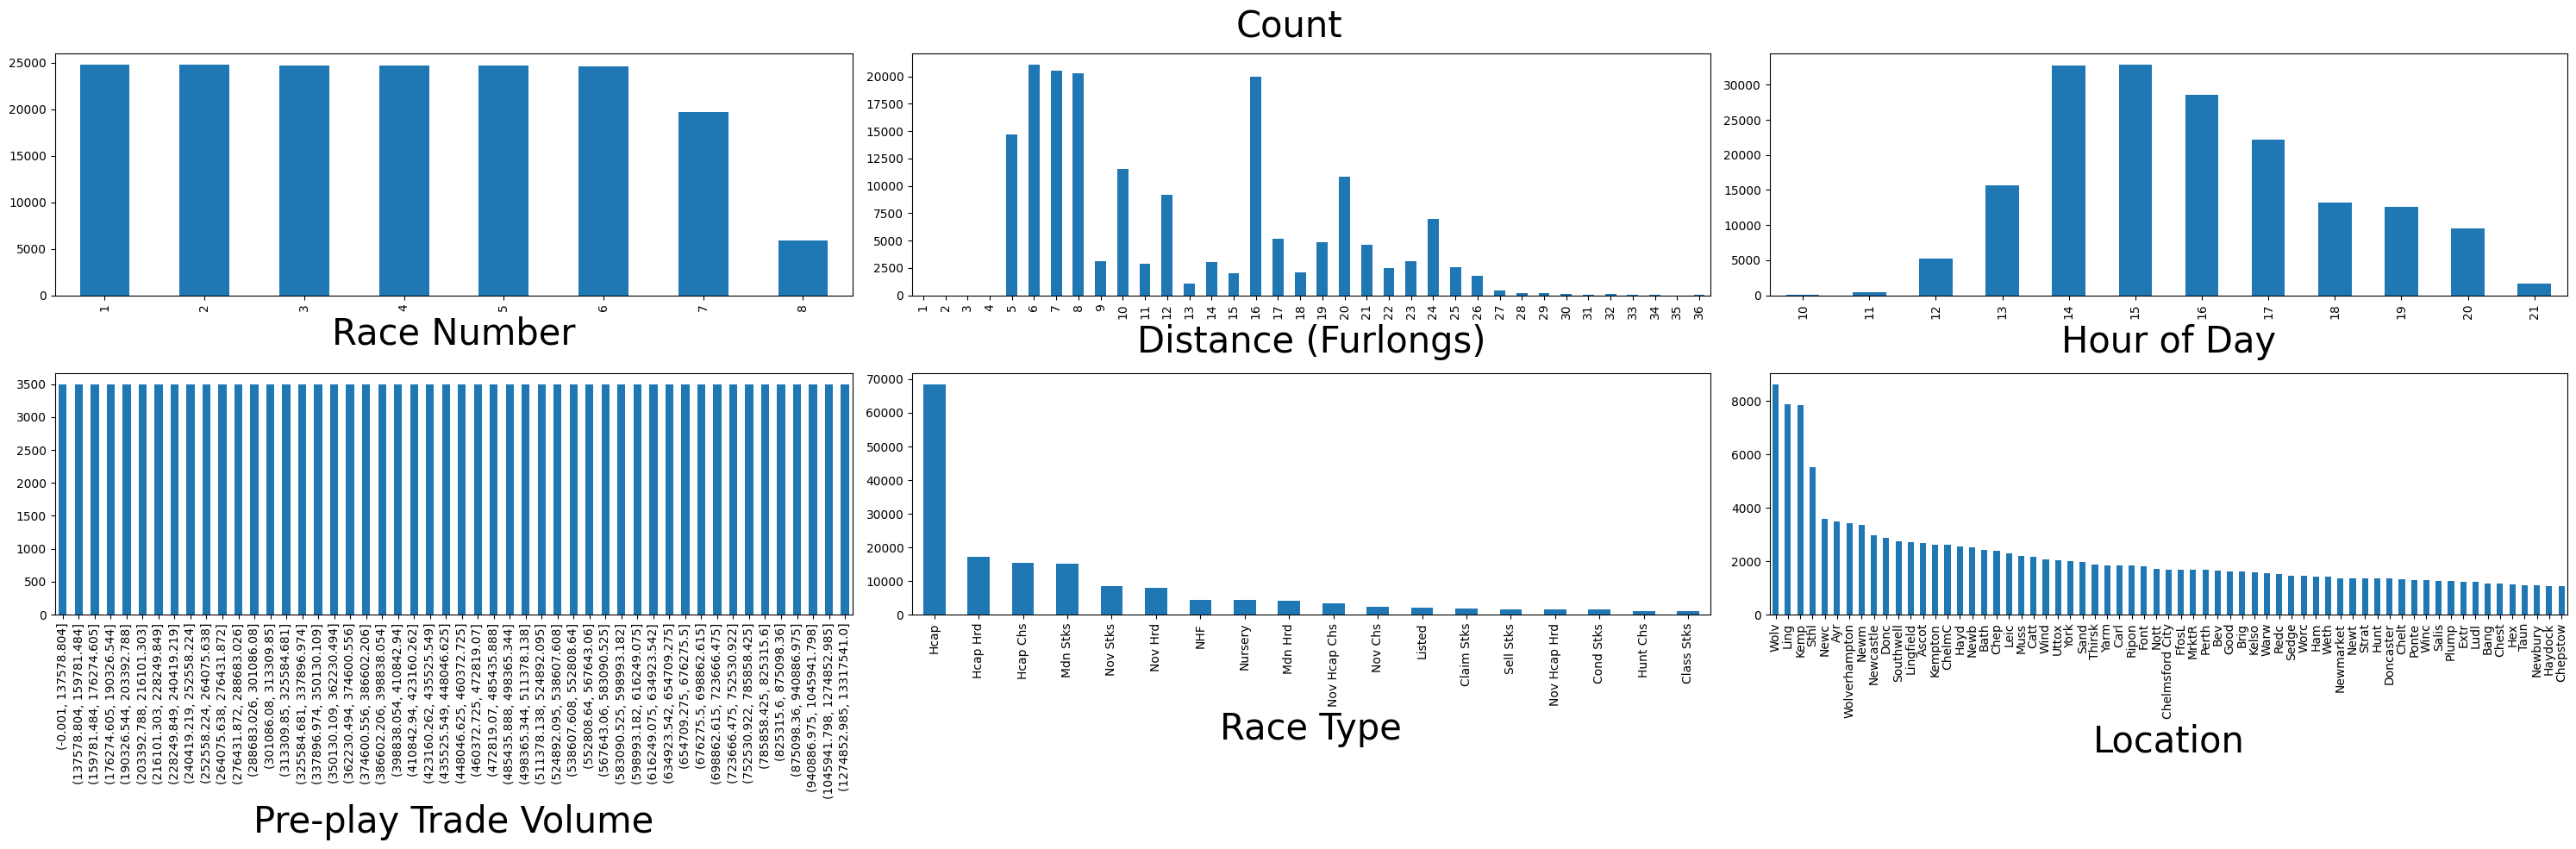

In [100]:
draw(lambda c: c.size(), "Count", kind="bar")

# Analysis

## Test Statistics

### Brier Score

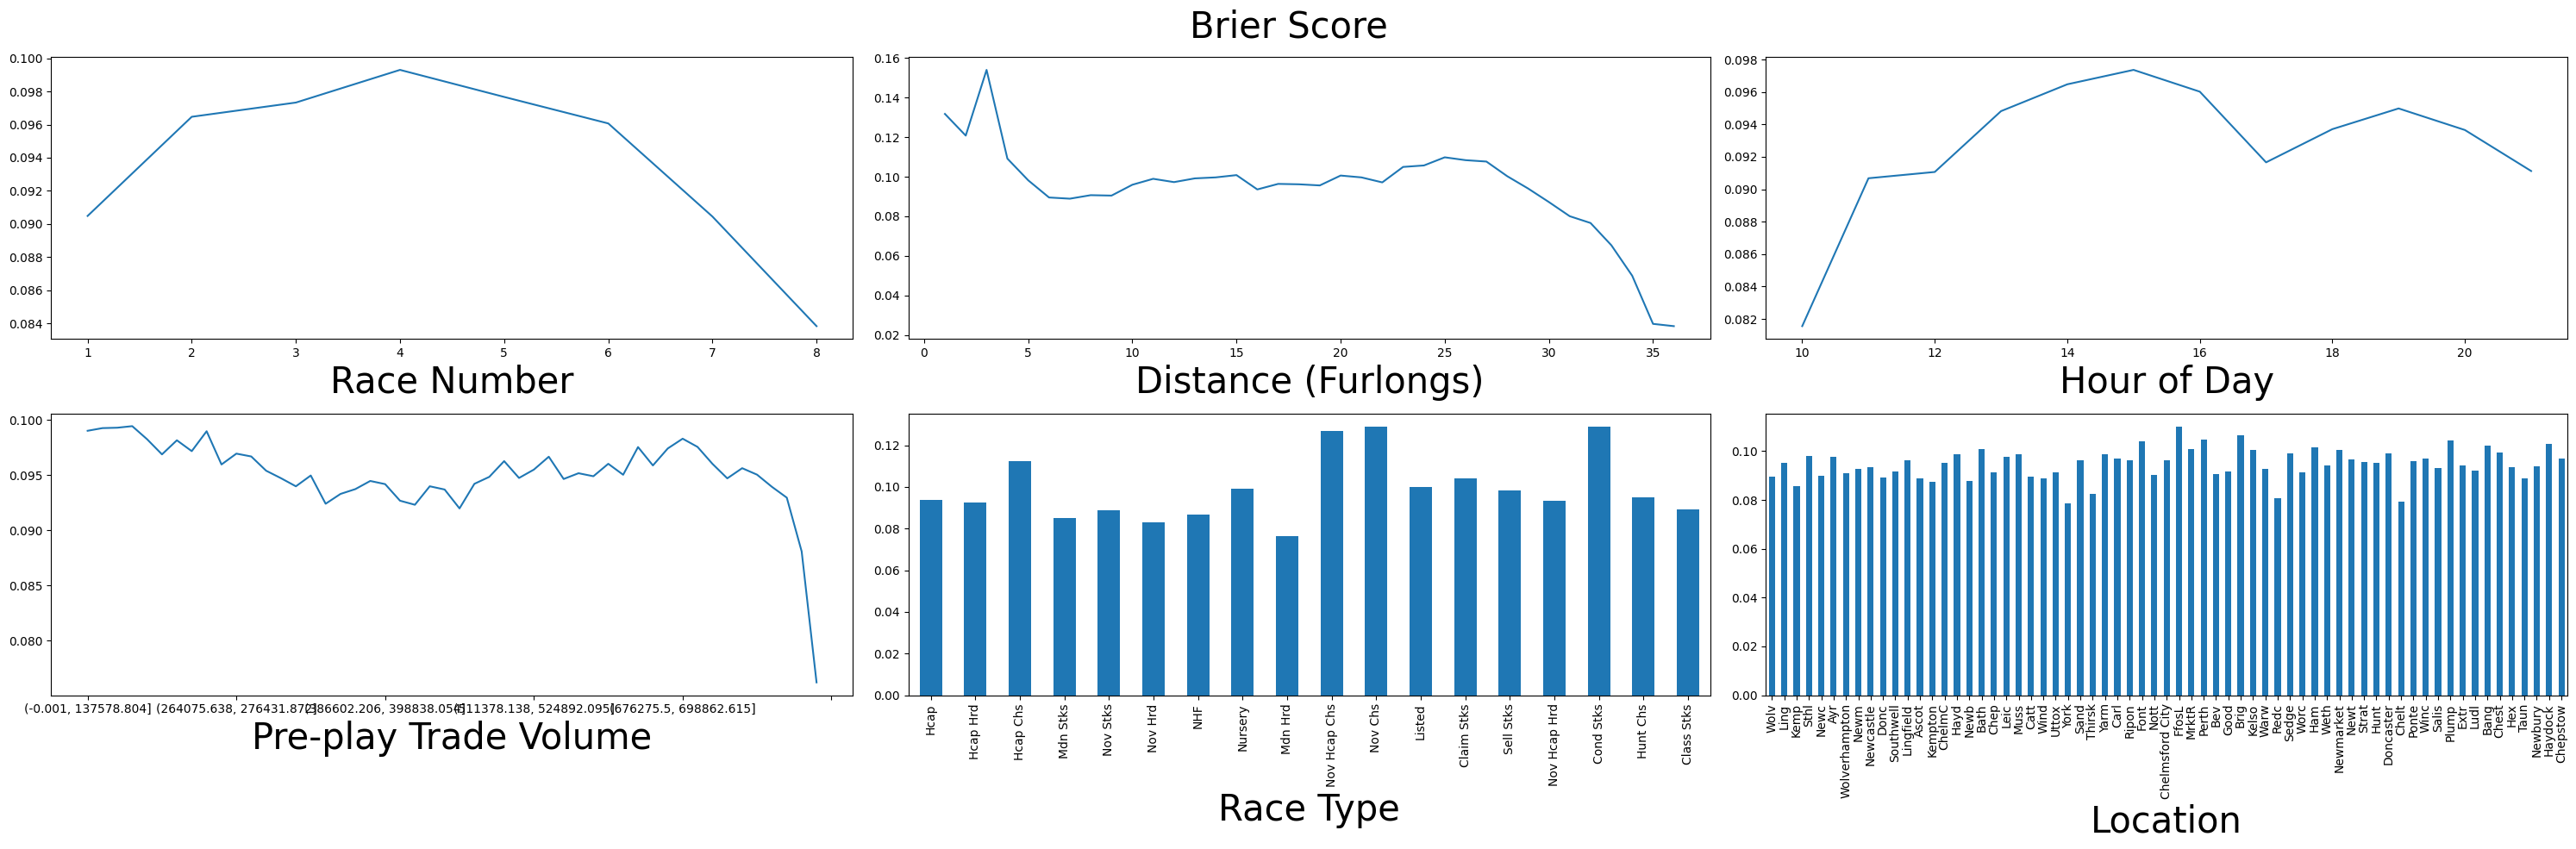

In [101]:
draw(lambda c: c.brier.mean(), "Brier Score")

### Log Loss

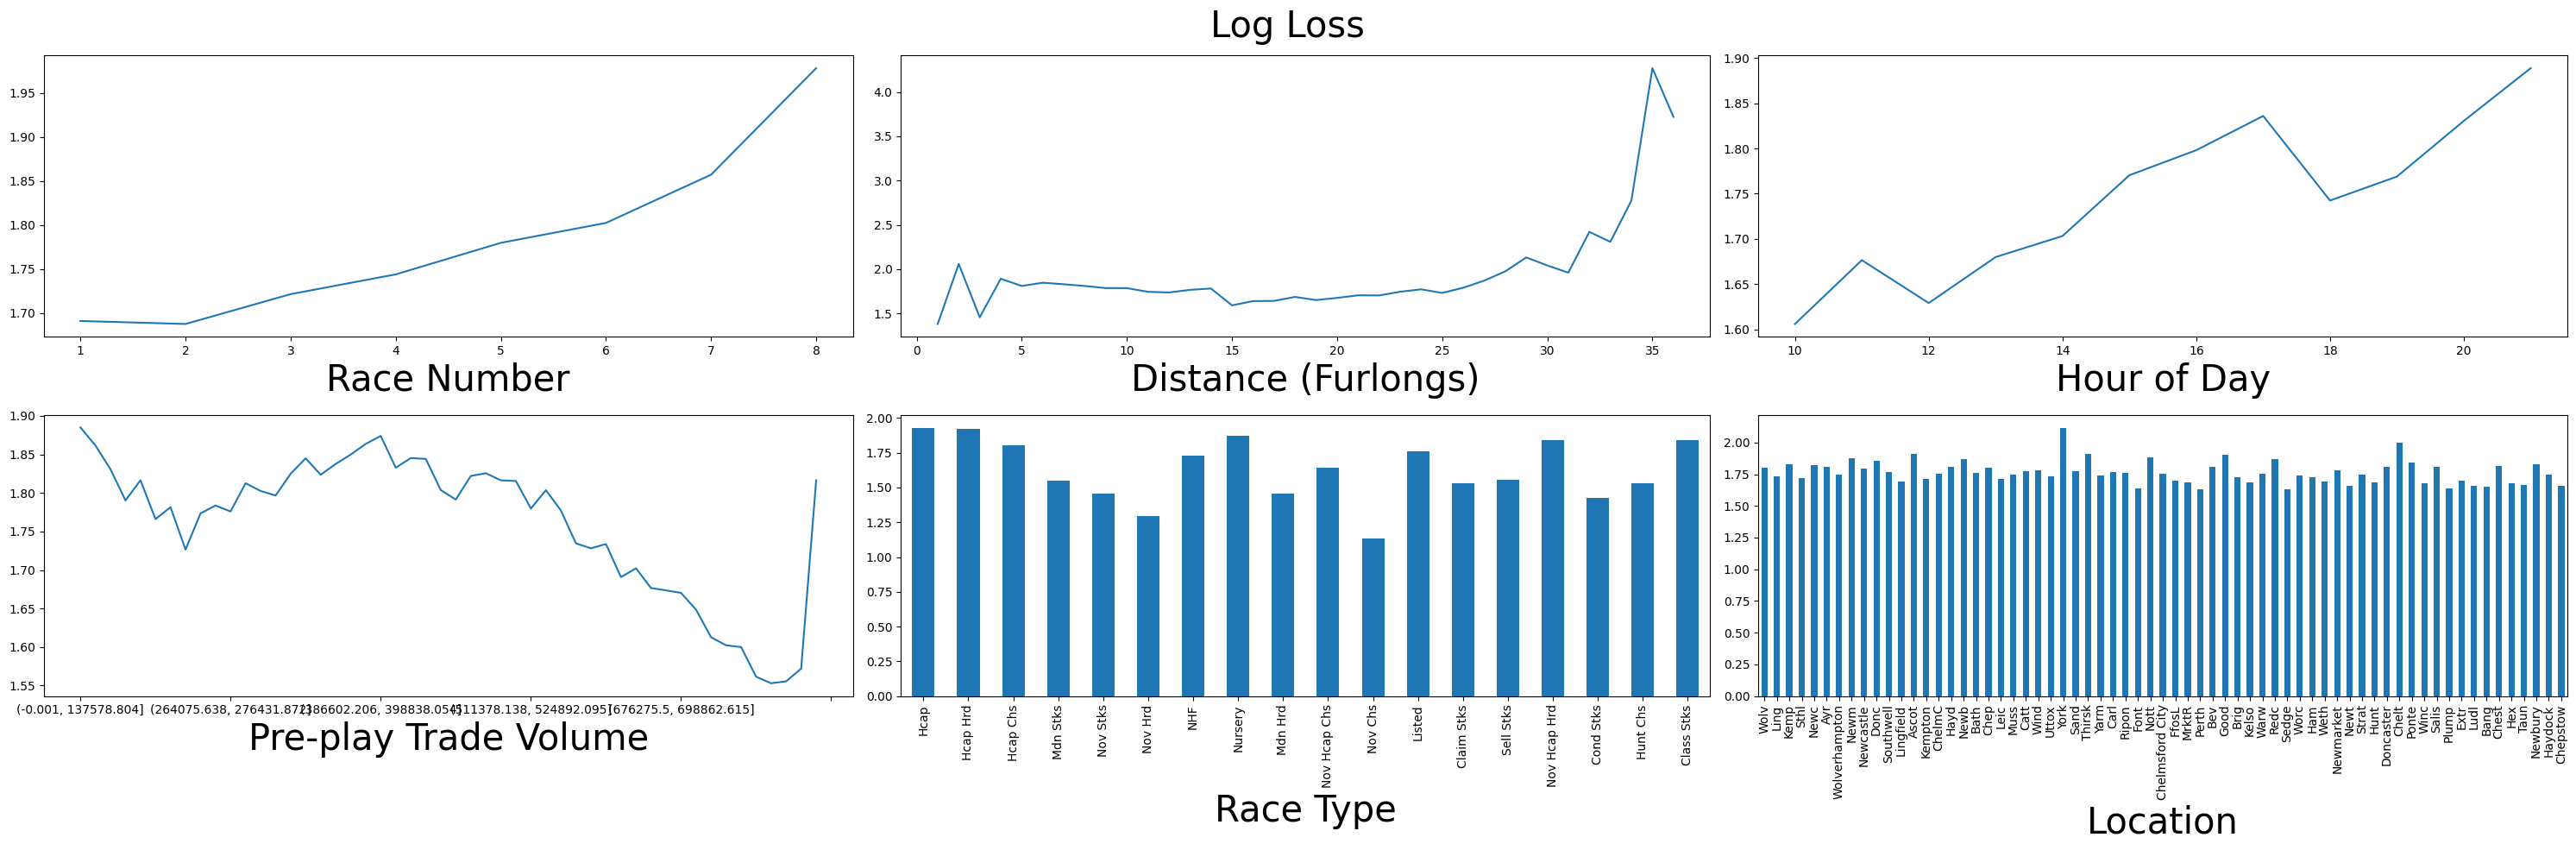

In [102]:
draw(lambda c: c.log_loss.mean(), "Log Loss")

## Trading Strategies

In [175]:
favs = runners.sort_values("bsp").groupby("race_id").head(1)

In [213]:
def run_strategy(f, race_groups=None):
    if race_groups is None:
        return f(runners)

    dfs = []
    groups = []
    for g, df in race_groups:
        groups += [g]
        dfs += [f(runners[runners.race_id.isin(df.index)])]
    return pd.concat(dfs, keys=groups, names=[race_groups.size().index.name, "selection_id"])

In [214]:
def create_bets(slip):
    bets=slip
    # generate timeline
    bets = bets.join(races[["race_time"]], on="race_id", how="inner").sort_values("race_time")
    # pnl
    bets["profit"] = (bets.bsp * bets.win_lose -1) * bets.liability

    bets["net_investment"] = bets.liability.cumsum()
    bets["net_profit"] = bets.profit.cumsum()
    
    return bets

### Bet on the Favourite

In [215]:
def bet_on_favourite(runners):
    favs = runners.sort_values("bsp").groupby("race_id").head(1)
    slip = favs[["race_id", "win_lose", "bsp"]]
    slip["liability"] = 1
    slip["back"] = True
    return create_bets(slip)

In [216]:
run_strategy(bet_on_favourite, races.groupby("race_no"))

race_id  win_lose       bsp  liability  back  \
race_no selection_id                                                   
1       1129962        21179929     False  3.384183          1  True   
        2786498        21179961      True  4.100000          1  True   
        3099701        21179945     False  5.298158          1  True   
        1457311        21181929      True  1.774441          1  True   
        1559113        21181099     False  3.802565          1  True   
...                         ...       ...       ...        ...   ...   
13      27404         107748960      True  3.588306          1  True   
        5600419       107845442      True  4.700000          1  True   
14      4136655       107748962     False  4.961095          1  True   
        3033493       107845444     False  2.417042          1  True   
15      6956858       107845446     False  1.833178          1  True   

                               race_time    profit  net_investment  net_profit  
race_no selection_id                                                            
1       1129962      2008-09-01 13:50:00 -1.000000               1   -1.000000  
        2786498      2008-09-01 14:10:00  3.100000               2    2.100000  
        3099701      2008-09-01 14:30:00 -1.000000               3    1.100000  
        1457311      2008-09-02 13:50:00  0.774441               4    1.874441  
        1559113      2008-09-02 14:00:00 -1.000000               5    0.874441  
...                                  ...       ...             ...         ...  
13      27404        2012-12-15 20:50:00  2.588306               1    2.588306  
        5600419      2013-01-04 18:30:00  3.700000               2    6.288306  
14      4136655      2012-12-15 21:20:00 -1.000000               1   -1.000000  
        3033493      2013-01-04 19:00:00 -1.000000               2   -2.000000  
15      6956858      2013-01-04 19:30:00 -1.000000               1   -1.000000  

[174779 rows x 9 columns]

In [182]:
def bet_on_favourite(race_groups):
    dfs = []
    for g, df in race_groups:
        f = favs[favs.race_id.isin(df.index)]
        dfs += [create_bets(
            favs.race_id,
            favs.index,
            favs.win_lose,
            np.full(len(favs), 1),
            favs.bsp,
            np.full(len(favs), True))]
    return pd.concat(dfs, keys=race_groups.groups.keys())

In [184]:
bet_on_favourite(races.groupby("race_no"))

race_id  selection_id  win_lose  liability     price  back  \
   selection_id                                                                 
1  1129962        21179929       1129962     False          1  3.384183  True   
   2786498        21179961       2786498      True          1  4.100000  True   
   3105499        21179931       3105499      True          1  2.678090  True   
   3099701        21179945       3099701     False          1  5.298158  True   
   2178483        21179963       2178483     False          1  3.416365  True   
...                    ...           ...       ...        ...       ...   ...   
15 84484375      257930827      84484375      True          1  4.696784  True   
   18834015      257930833      18834015     False          1  2.360000  True   
   3216291       257930844       3216291      True          1  2.479131  True   
   45004509      257930839      45004509      True          1  2.260000  True   
   78928899      257930851      78928899     False          1  2.960000  True   

                          race_time    profit  net_investment  net_profit  
   selection_id                                                            
1  1129962      2008-09-01 13:50:00 -1.000000               1   -1.000000  
   2786498      2008-09-01 14:10:00  3.100000               2    2.100000  
   3105499      2008-09-01 14:20:00  1.678090               3    3.778090  
   3099701      2008-09-01 14:30:00 -1.000000               4    2.778090  
   2178483      2008-09-01 14:40:00 -1.000000               5    1.778090  
...                             ...       ...             ...         ...  
15 84484375     2026-05-10 14:52:00  3.696784          174775  941.375034  
   18834015     2026-05-10 15:27:00 -1.000000          174776  940.375034  
   3216291      2026-05-10 16:02:00  1.479131          174777  941.854165  
   45004509     2026-05-10 16:37:00  1.260000          174778  943.114165  
   78928899     2026-05-10 17:10:00 -1.000000          174779  942.114165  

[2621685 rows x 10 columns]

In [172]:
dfs = []
for g, df in races.groupby("race_no"):
    dfs += [favs[favs.race_id.isin(df.index)]]

In [205]:
races.groupby("race_no").size().index.name

'race_no'